Dataset Head:


,ProductID,Category,Region,Sales,Discount,Quantity,Rating,Profit,Marketing_Spend,Review
0,PROD_000,Office Supplies,East,272.087465,0.297685,6,4,18.856980,36.589866,useful organized neat paper pen write delivery...
1,PROD_001,Toys,East,196.624536,0.272416,5,4,-40.151663,24.794826,fun safe creative kid happy joy play color gam...
2,PROD_002,Home,East,224.984872,0.095003,9,2,45.961222,25.338253,beautiful design clean practical sturdy dynami...
3,PROD_003,Toys,South,244.710329,0.160089,1,3,14.474564,15.447214,fun safe creative kid happy joy play color gam...
4,PROD_004,Toys,South,994.145521,0.191086,5,4,57.589692,52.940852,fun safe creative kid happy joy play color gam...


/tmp/ipykernel_2244/618065863.py:51: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Category', y='Sales', estimator=np.mean, ci=None, palette='viridis')
/tmp/ipykernel_2244/618065863.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Category', y='Sales', estimator=np.mean, ci=None, palette='viridis')


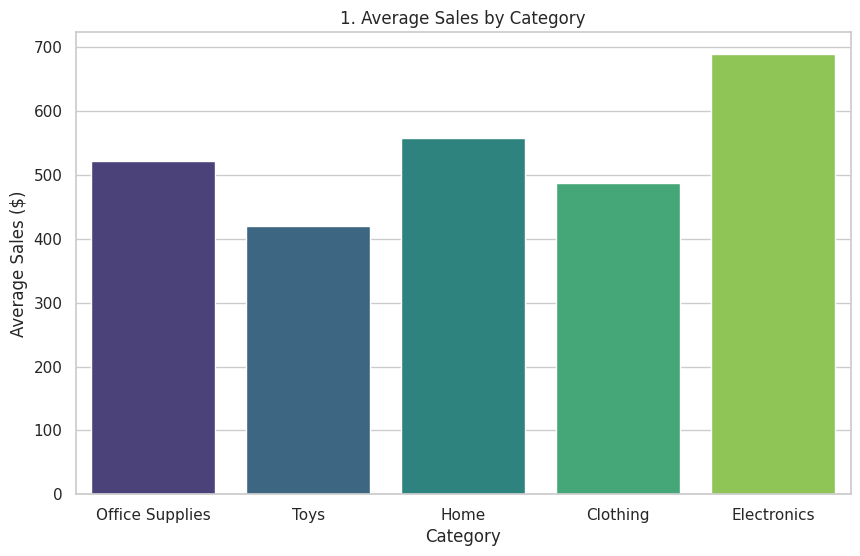

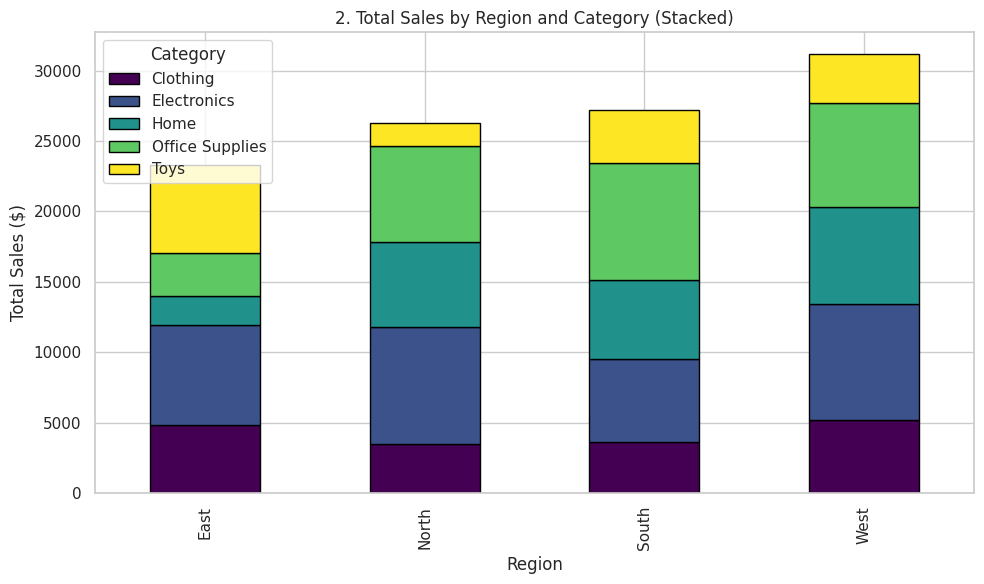

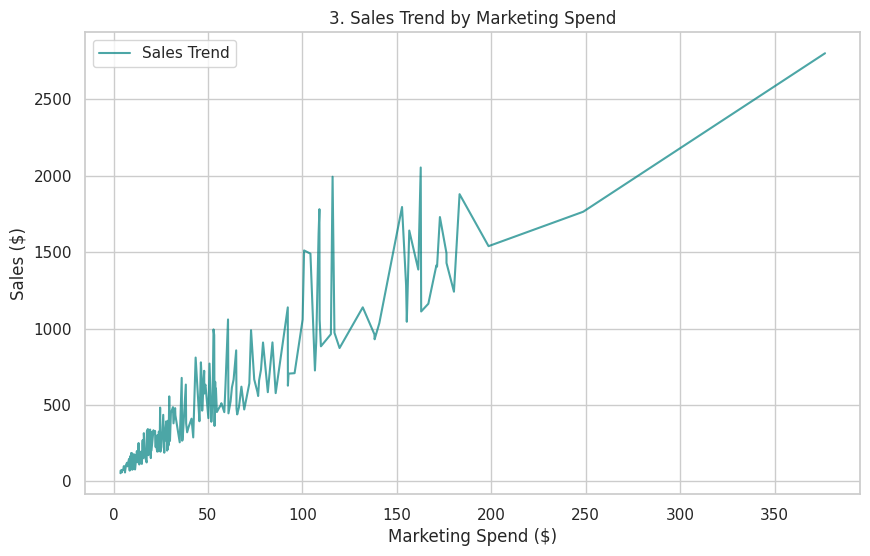

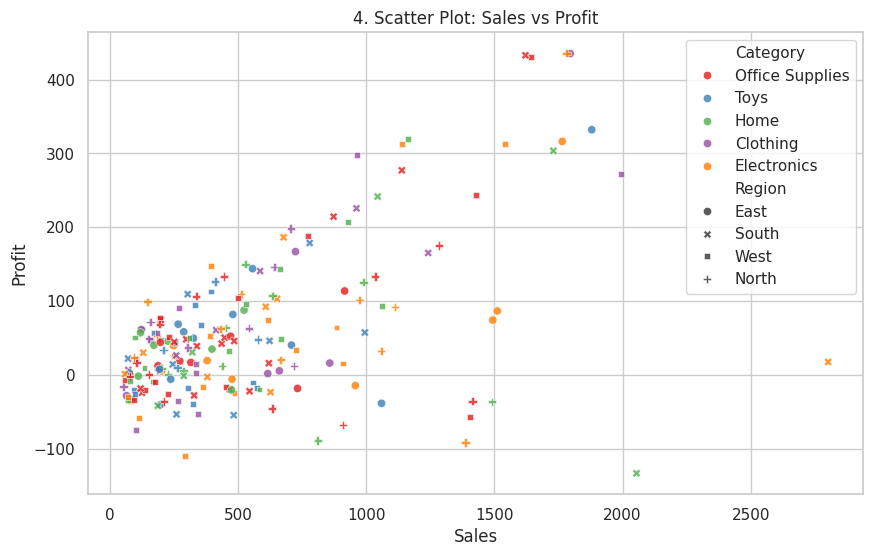

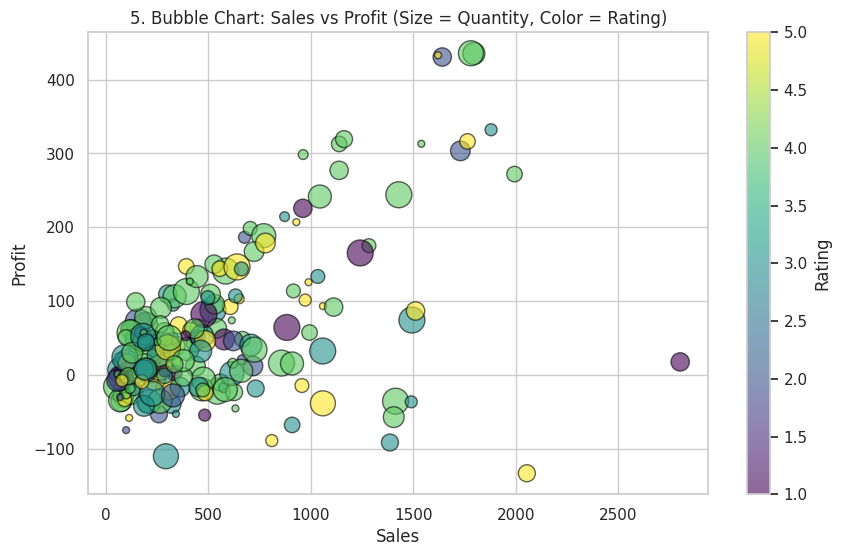

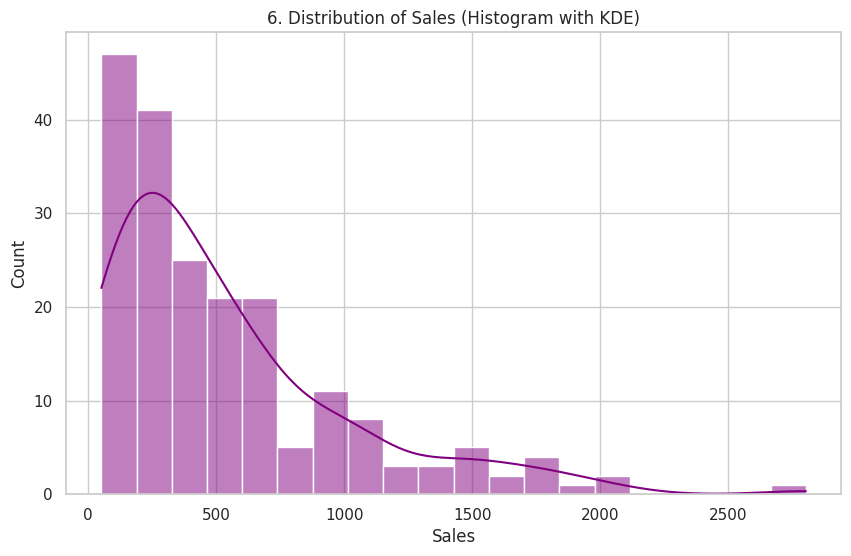

/tmp/ipykernel_2244/618065863.py:100: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Category', y='Profit', palette='Pastel1')


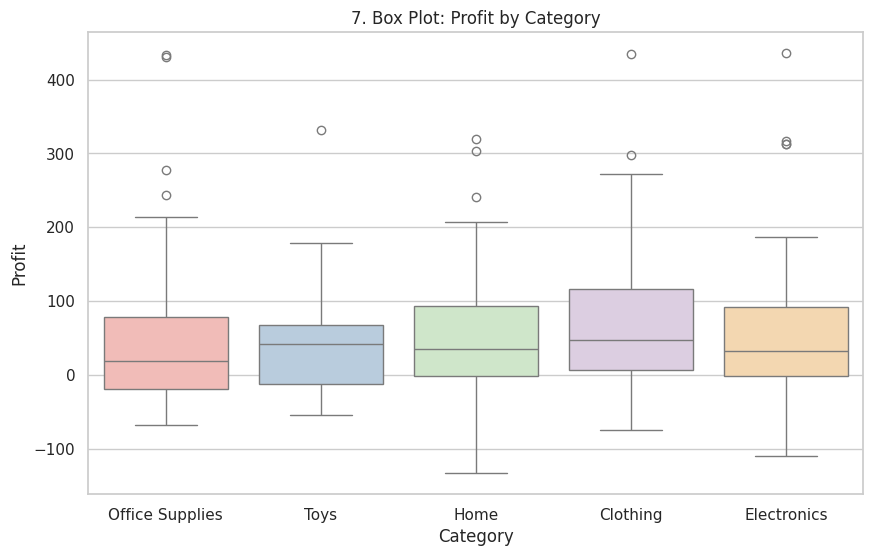

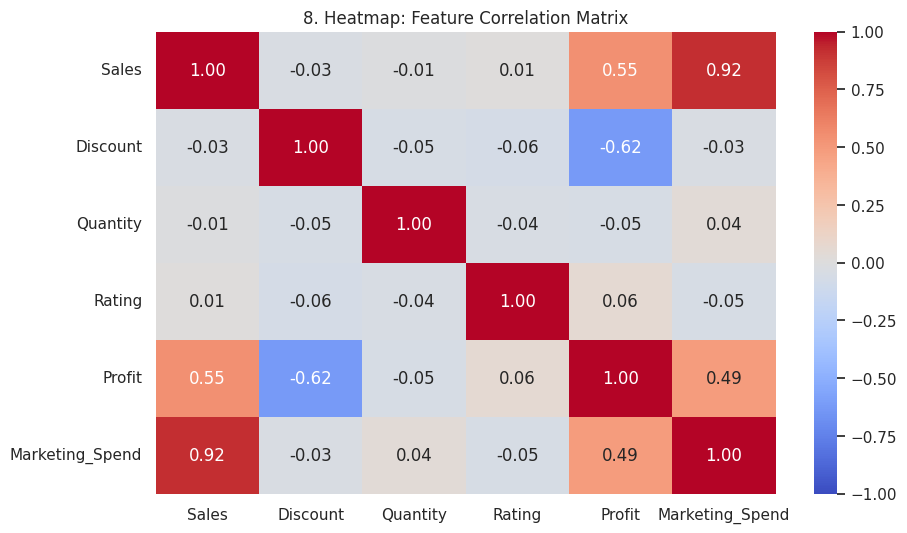

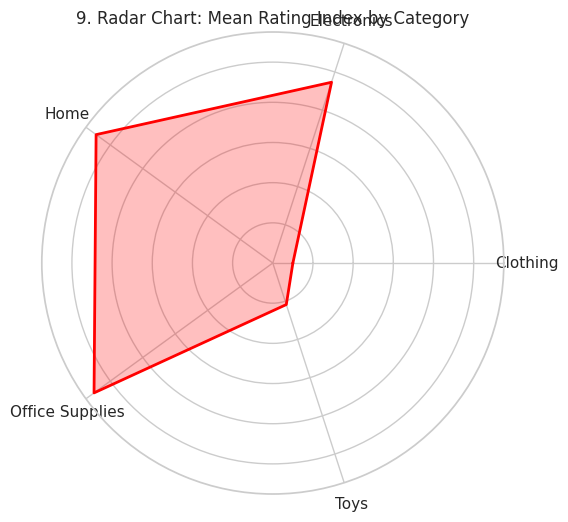

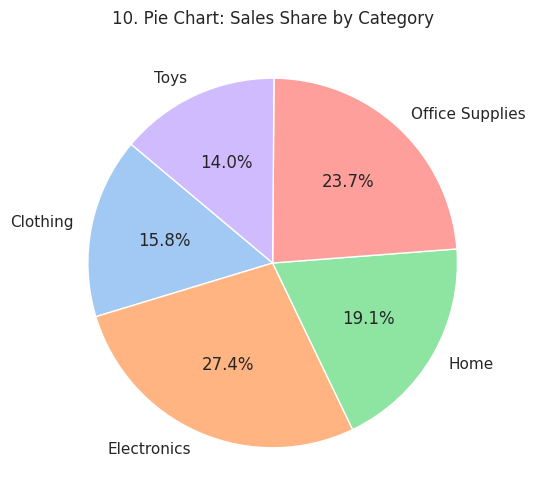

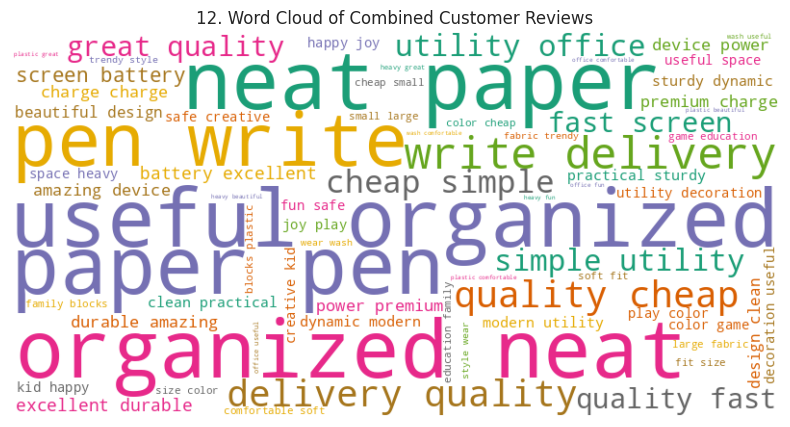

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from wordcloud import WordCloud

# 1. Generate a synthetic multivariate dataset
np.random.seed(42)
n_samples = 200

categories = ['Electronics', 'Clothing', 'Home', 'Office Supplies', 'Toys']
regions = ['North', 'East', 'South', 'West']

data = {
    'ProductID': [f'PROD_{i:03d}' for i in range(n_samples)],
    'Category': np.random.choice(categories, n_samples),
    'Region': np.random.choice(regions, n_samples),
    'Sales': np.random.exponential(scale=500, size=n_samples) + 50,
    'Discount': np.random.uniform(0.0, 0.4, n_samples),
    'Quantity': np.random.randint(1, 15, size=n_samples),
    'Rating': np.random.choice([1, 2, 3, 4, 5], n_samples, p=[0.05, 0.1, 0.2, 0.45, 0.2])
}

df = pd.DataFrame(data)
# Calculate dependent features to build relationships
df['Profit'] = (df['Sales'] * (0.3 - df['Discount'])) + np.random.normal(0, 30, n_samples)
df['Marketing_Spend'] = df['Sales'] * np.random.uniform(0.05, 0.15, n_samples)

# Text reviews for Word Cloud generation
reviews = {
    'Electronics': 'great quality fast screen battery excellent durable amazing device power premium charge charge',
    'Clothing': 'comfortable soft fit size color cheap small large fabric trendy style wear wash',
    'Home': 'beautiful design clean practical sturdy dynamic modern utility decoration useful space heavy',
    'Office Supplies': 'useful organized neat paper pen write delivery quality cheap simple utility office',
    'Toys': 'fun safe creative kid happy joy play color game education family blocks plastic'
}
df['Review'] = df['Category'].map(reviews)

print("Dataset Head:")
display(df.head())

# Set Seaborn / Matplotlib styling
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# -----------------------------------------------------
# 1. Bar Chart: Average Sales by Category
plt.figure()
sns.barplot(data=df, x='Category', y='Sales', estimator=np.mean, ci=None, palette='viridis')
plt.title('1. Average Sales by Category')
plt.ylabel('Average Sales ($)')
plt.show()

# 2. Stacked Bar Chart: Sales by Region and Category
pivot_df = df.pivot_table(index='Region', columns='Category', values='Sales', aggfunc='sum')
pivot_df.plot(kind='bar', stacked=True, colormap='viridis', edgecolor='black')
plt.title('2. Total Sales by Region and Category (Stacked)')
plt.ylabel('Total Sales ($)')
plt.legend(title='Category')
plt.tight_layout()
plt.show()

# 3. Line Chart: Trend of Sales vs Marketing Spend (sorted by Marketing Spend)
sort_df = df.sort_values(by='Marketing_Spend')
plt.figure()
plt.plot(sort_df['Marketing_Spend'], sort_df['Sales'], color='teal', alpha=0.7, label='Sales Trend')
plt.title('3. Sales Trend by Marketing Spend')
plt.xlabel('Marketing Spend ($)')
plt.ylabel('Sales ($)')
plt.legend()
plt.show()

# 4. Scatter Plot: Sales vs Profit
plt.figure()
sns.scatterplot(data=df, x='Sales', y='Profit', hue='Category', style='Region', palette='Set1', alpha=0.8)
plt.title('4. Scatter Plot: Sales vs Profit')
plt.show()

# 5. Bubble Chart: Sales vs Profit vs Quantity (Size) & Rating (Color)
plt.figure()
scatter = plt.scatter(x=df['Sales'], y=df['Profit'],
                      s=df['Quantity']*25, c=df['Rating'],
                      cmap='viridis', alpha=0.6, edgecolors='black')
plt.title('5. Bubble Chart: Sales vs Profit (Size = Quantity, Color = Rating)')
plt.xlabel('Sales')
plt.ylabel('Profit')
plt.colorbar(scatter, label='Rating')
plt.show()

# 6. Histogram: Distribution of Sales
plt.figure()
sns.histplot(df['Sales'], bins=20, kde=True, color='purple')
plt.title('6. Distribution of Sales (Histogram with KDE)')
plt.show()

# 7. Box Plot: Distribution of Profit by Category (Identifying Outliers)
plt.figure()
sns.boxplot(data=df, x='Category', y='Profit', palette='Pastel1')
plt.title('7. Box Plot: Profit by Category')
plt.show()

# 8. Heatmap: Correlation of Numerical Variables
plt.figure()
corr = df[['Sales', 'Discount', 'Quantity', 'Rating', 'Profit', 'Marketing_Spend']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('8. Heatmap: Feature Correlation Matrix')
plt.show()

# 9. Radar Chart: Mean Ratings across Categories
cat_means = df.groupby('Category')[['Rating', 'Quantity', 'Discount']].mean()
# Normalize values for plotting on same radar scale
cat_means_norm = (cat_means - cat_means.min()) / (cat_means.max() - cat_means.min()) + 0.1

categories_list = list(cat_means_norm.index)
values = cat_means_norm['Rating'].tolist()
values += values[:1]
angles = np.linspace(0, 2*np.pi, len(categories_list), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
ax.fill(angles, values, color='red', alpha=0.25)
ax.plot(angles, values, color='red', linewidth=2)
ax.set_yticklabels([])
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories_list)
plt.title('9. Radar Chart: Mean Rating Index by Category')
plt.show()

# 10. Pie Chart: Market Share of Total Sales by Category
sales_by_cat = df.groupby('Category')['Sales'].sum()
plt.figure()
plt.pie(sales_by_cat, labels=sales_by_cat.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('10. Pie Chart: Sales Share by Category')
plt.show()

# 11. Tree Map: Hierarchical Category and Region Sales distribution
fig_tree = px.treemap(df, path=['Category', 'Region'], values='Sales',
                      title='11. Tree Map: Hierarchy of Sales by Category and Region',
                      color='Profit', color_continuous_scale='RdYlGn')
fig_tree.show()

# 12. Word Cloud: Visualizing common terms in customer reviews
text_corpus = " ".join(df['Review'].dropna().tolist())
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='Dark2').generate(text_corpus)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('12. Word Cloud of Combined Customer Reviews')
plt.show()



Wine Dataset Head:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


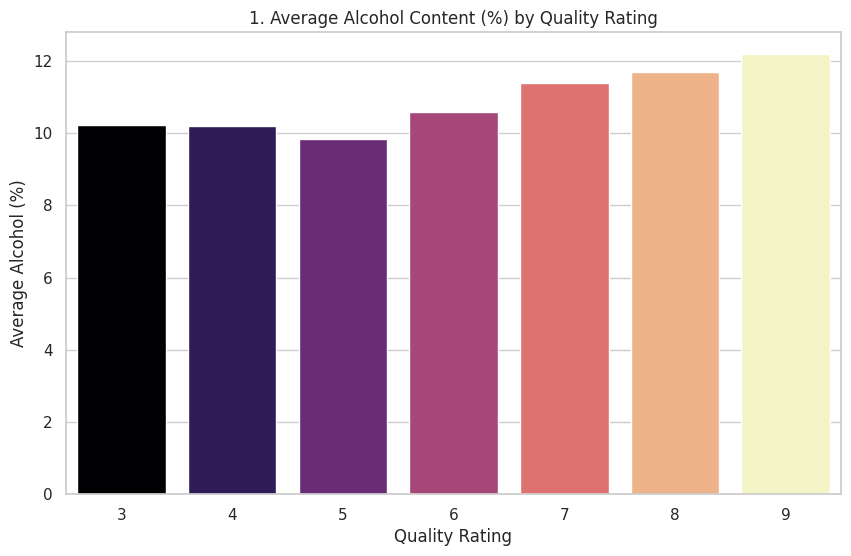

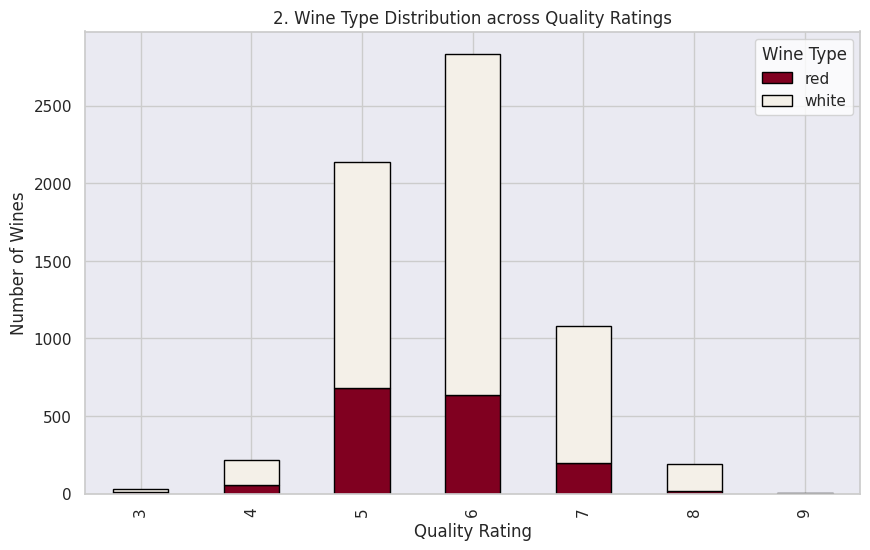

/tmp/ipykernel_2244/3113340067.py:44: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



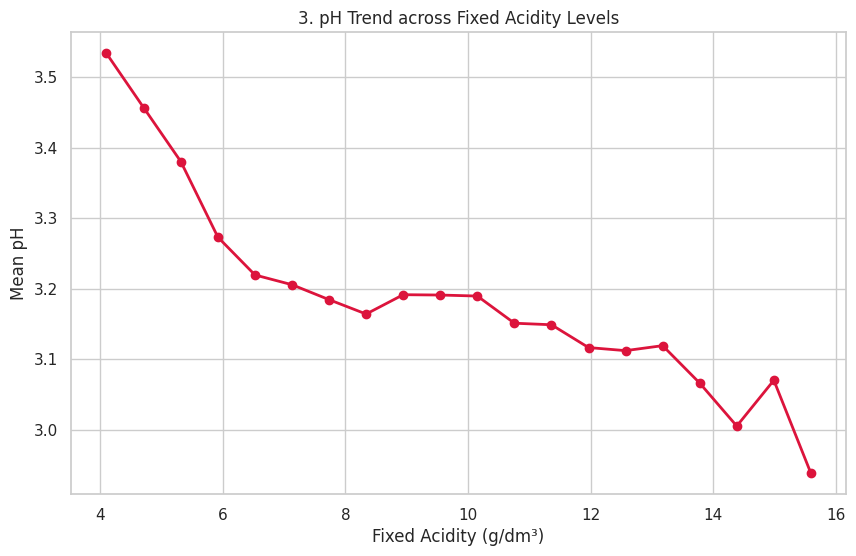

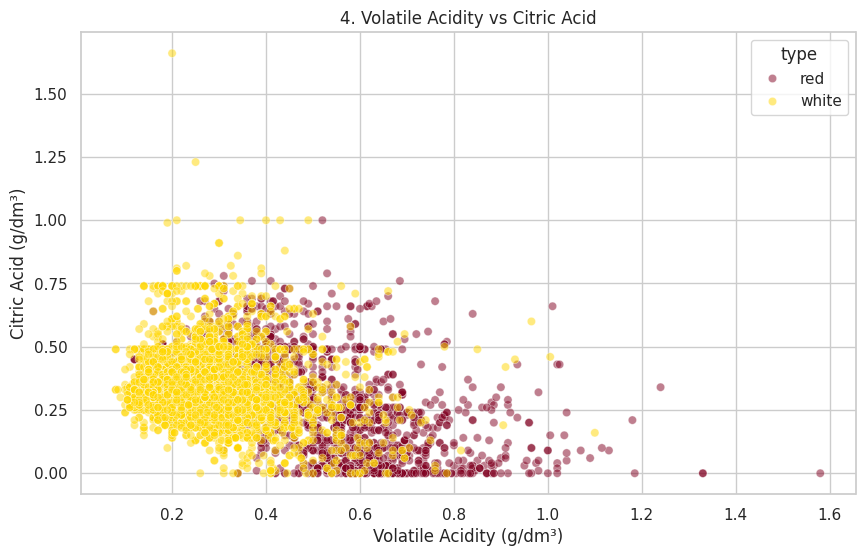

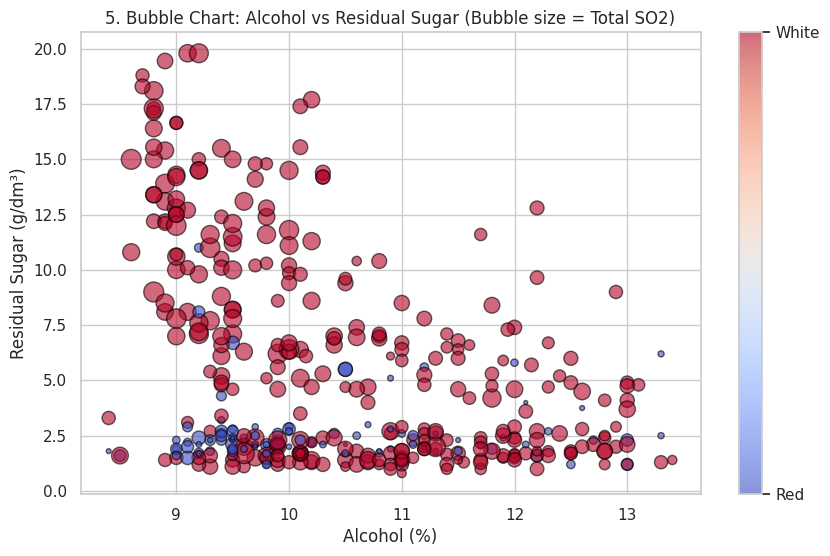

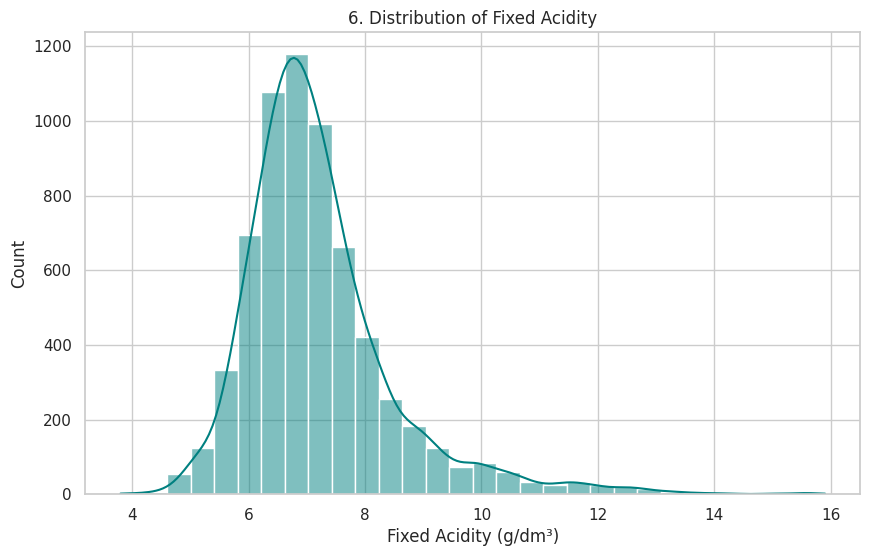

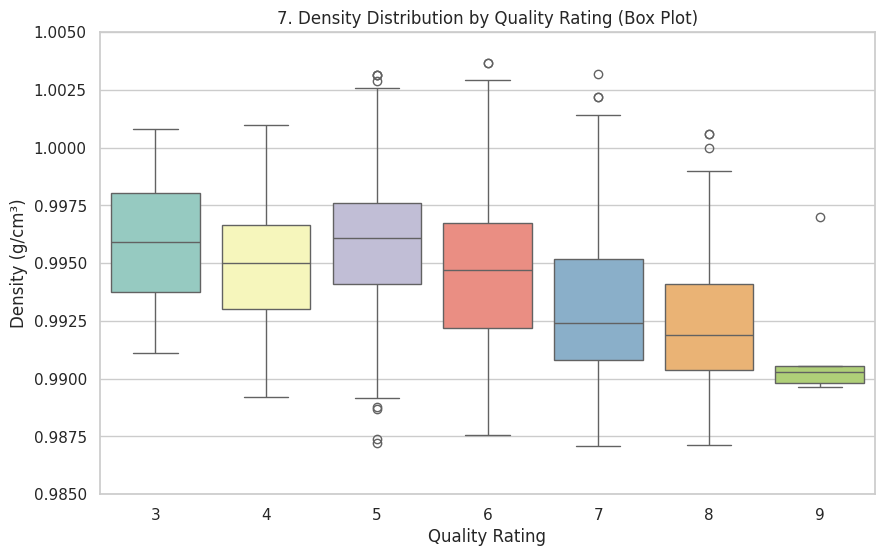

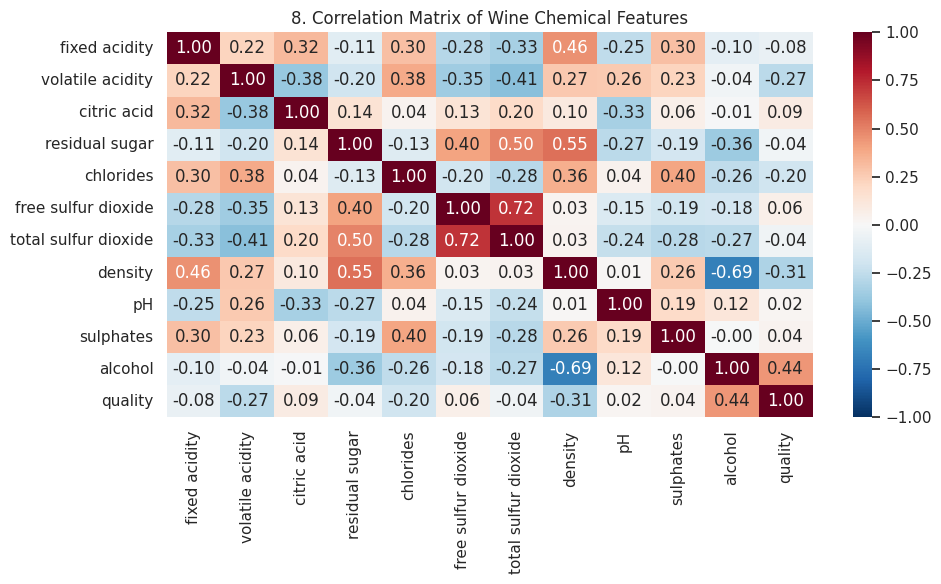

/tmp/ipykernel_2244/3113340067.py:107: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_2244/3113340067.py:118: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`

/tmp/ipykernel_2244/3113340067.py:123: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



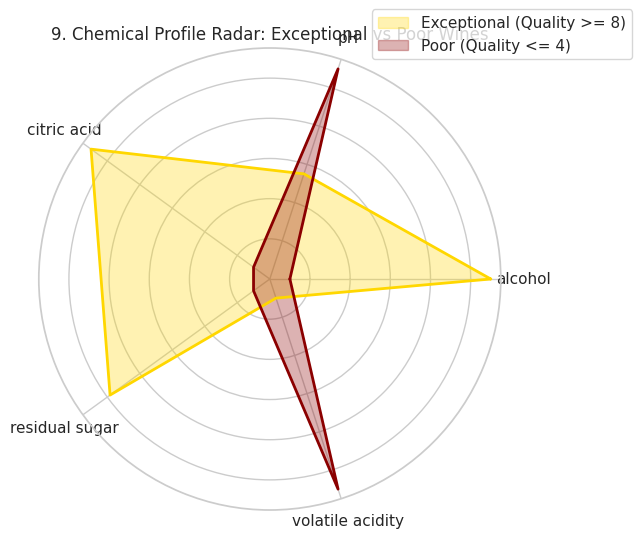

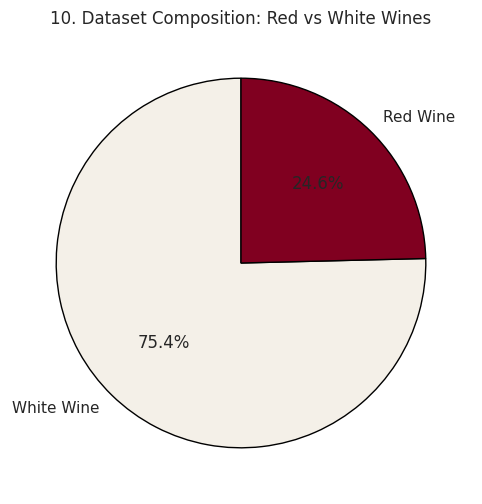

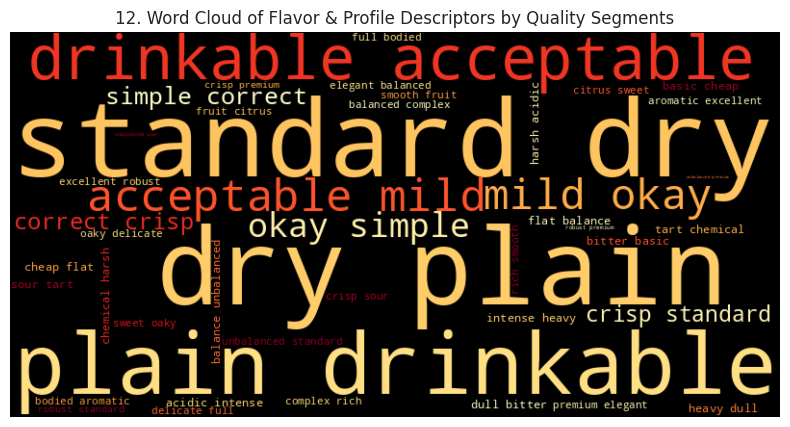

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from wordcloud import WordCloud

# 1. Load and prepare the Wine Quality Dataset
red_wine = pd.read_csv('/content/Wine_quality_dataset/winequality-red.csv', sep=';')
white_wine = pd.read_csv('/content/Wine_quality_dataset/winequality-white.csv', sep=';')

# Add identifier column
red_wine['type'] = 'red'
white_wine['type'] = 'white'

# Combine datasets
wine_df = pd.concat([red_wine, white_wine], ignore_index=True)
print("Wine Dataset Head:")
display(wine_df.head())

# Set Seaborn theme
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# --- 1. Bar Chart: Average Alcohol by Quality Rating ---
plt.figure()
sns.barplot(data=wine_df, x='quality', y='alcohol', errorbar=None, palette='magma', hue='quality', legend=False)
plt.title('1. Average Alcohol Content (%) by Quality Rating')
plt.xlabel('Quality Rating')
plt.ylabel('Average Alcohol (%)')
plt.show()

# --- 2. Stacked Bar Chart: Count of Wine Types across Quality Classes ---
pivot_type_qual = wine_df.groupby(['quality', 'type']).size().unstack(fill_value=0)
pivot_type_qual.plot(kind='bar', stacked=True, color=['#800020', '#F4F0E8'], edgecolor='black')
plt.title('2. Wine Type Distribution across Quality Ratings')
plt.xlabel('Quality Rating')
plt.ylabel('Number of Wines')
plt.legend(title='Wine Type')
plt.gca().set_facecolor('#eaeaf2')
plt.show()

# --- 3. Line Chart: Trend of pH vs Fixed Acidity (aggregated mean trend) ---
acidity_trend = wine_df.groupby(pd.cut(wine_df['fixed acidity'], bins=20))['pH'].mean().reset_index()
acidity_trend['fixed acidity_mid'] = acidity_trend['fixed acidity'].apply(lambda x: x.mid)
plt.figure()
plt.plot(acidity_trend['fixed acidity_mid'], acidity_trend['pH'], marker='o', color='crimson', linewidth=2)
plt.title('3. pH Trend across Fixed Acidity Levels')
plt.xlabel('Fixed Acidity (g/dm³)')
plt.ylabel('Mean pH')
plt.show()

# --- 4. Scatter Plot: Volatile Acidity vs Citric Acid ---
plt.figure()
sns.scatterplot(data=wine_df, x='volatile acidity', y='citric acid', hue='type', palette={'red': '#800020', 'white': '#FFD700'}, alpha=0.5)
plt.title('4. Volatile Acidity vs Citric Acid')
plt.xlabel('Volatile Acidity (g/dm³)')
plt.ylabel('Citric Acid (g/dm³)')
plt.show()

# --- 5. Bubble Chart: Alcohol vs Residual Sugar (Size = Total Sulfur Dioxide, Color = Wine Type) ---
sample_df = wine_df.sample(400, random_state=42)  # Sample for clear visualization
plt.figure()
scatter = plt.scatter(
    x=sample_df['alcohol'],
    y=sample_df['residual sugar'],
    s=sample_df['total sulfur dioxide'] * 0.8,
    c=sample_df['type'].map({'red': 0, 'white': 1}),
    cmap='coolwarm',
    alpha=0.6,
    edgecolors='black'
)
plt.title('5. Bubble Chart: Alcohol vs Residual Sugar (Bubble size = Total SO2)')
plt.xlabel('Alcohol (%)')
plt.ylabel('Residual Sugar (g/dm³)')
plt.colorbar(scatter, ticks=[0, 1], format=plt.FuncFormatter(lambda val, loc: ['Red', 'White'][int(val)]))
plt.show()

# --- 6. Histogram: Distribution of Fixed Acidity ---
plt.figure()
sns.histplot(data=wine_df, x='fixed acidity', kde=True, color='teal', bins=30)
plt.title('6. Distribution of Fixed Acidity')
plt.xlabel('Fixed Acidity (g/dm³)')
plt.show()

# --- 7. Box Plot: Distribution of Density by Quality ---
plt.figure()
sns.boxplot(data=wine_df, x='quality', y='density', palette='Set3', hue='quality', legend=False)
plt.title('7. Density Distribution by Quality Rating (Box Plot)')
plt.xlabel('Quality Rating')
plt.ylabel('Density (g/cm³)')
plt.ylim(0.985, 1.005) # Zoom in for clarity
plt.show()

# --- 8. Heatmap: Correlation of Chemical Variables ---
plt.figure()
corr_matrix = wine_df.drop('type', axis=1).corr()
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', fmt='.2f', vmin=-1, vmax=1)
plt.title('8. Correlation Matrix of Wine Chemical Features')
plt.tight_layout()
plt.show()

# --- 9. Radar Chart: Chemical Profiles of Exceptional (Quality >= 8) vs Poor (Quality <= 4) Wines ---
quality_groups = wine_df.copy()
quality_groups['segment'] = pd.cut(quality_groups['quality'], bins=[0, 4, 7, 10], labels=['Poor', 'Average', 'Exceptional'])
features_to_radar = ['alcohol', 'pH', 'citric acid', 'residual sugar', 'volatile acidity']
radar_data = quality_groups.groupby('segment')[features_to_radar].mean()

# Normalize features between 0.1 and 1.1 for clear visualization
radar_data_norm = (radar_data - radar_data.min()) / (radar_data.max() - radar_data.min()) + 0.1

categories_radar = list(radar_data_norm.columns)
angles = np.linspace(0, 2*np.pi, len(categories_radar), endpoint=False).tolist() + [0]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))

# Exceptional Wine Profile
values_exp = radar_data_norm.loc['Exceptional'].tolist() + [radar_data_norm.loc['Exceptional'][0]]
ax.fill(angles, values_exp, color='gold', alpha=0.3, label='Exceptional (Quality >= 8)')
ax.plot(angles, values_exp, color='gold', linewidth=2)

# Poor Wine Profile
values_poor = radar_data_norm.loc['Poor'].tolist() + [radar_data_norm.loc['Poor'][0]]
ax.fill(angles, values_poor, color='darkred', alpha=0.3, label='Poor (Quality <= 4)')
ax.plot(angles, values_poor, color='darkred', linewidth=2)

ax.set_yticklabels([])
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories_radar)
plt.title('9. Chemical Profile Radar: Exceptional vs Poor Wines')
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()

# --- 10. Pie Chart: Proportional Share of Red vs White Wines ---
type_counts = wine_df['type'].value_counts()
plt.figure()
plt.pie(type_counts, labels=['White Wine', 'Red Wine'], autopct='%1.1f%%', startangle=90, colors=['#F4F0E8', '#800020'], wedgeprops=dict(edgecolor='black'))
plt.title('10. Dataset Composition: Red vs White Wines')
plt.show()

# --- 11. Tree Map: Hierarchy of Average Alcohol by Type and Quality ---
tree_df = wine_df.groupby(['type', 'quality'])['alcohol'].mean().reset_index(name='mean_alcohol')
fig_tree = px.treemap(
    tree_df,
    path=['type', 'quality'],
    values='mean_alcohol',
    color='mean_alcohol',
    color_continuous_scale='Portland',
    title='11. Tree Map: Average Alcohol Content by Wine Type and Quality'
)
fig_tree.show()

# --- 12. Word Cloud: Text-based descriptors based on Quality Segments ---
descriptor_map = {
    'Poor': 'sour tart chemical harsh acidic intense heavy dull bitter basic cheap flat balance unbalanced',
    'Average': 'standard dry plain drinkable acceptable mild okay simple correct crisp',
    'Exceptional': 'premium elegant balanced complex rich smooth fruit citrus sweet oaky delicate full-bodied aromatic excellent robust'
}

text_list = quality_groups['segment'].map(descriptor_map).dropna().tolist()
text_corpus = " ".join(text_list)

wordcloud = WordCloud(width=800, height=400, background_color='black', colormap='YlOrRd').generate(text_corpus)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('12. Word Cloud of Flavor & Profile Descriptors by Quality Segments')
plt.show()

Dataset shape: (569, 33)


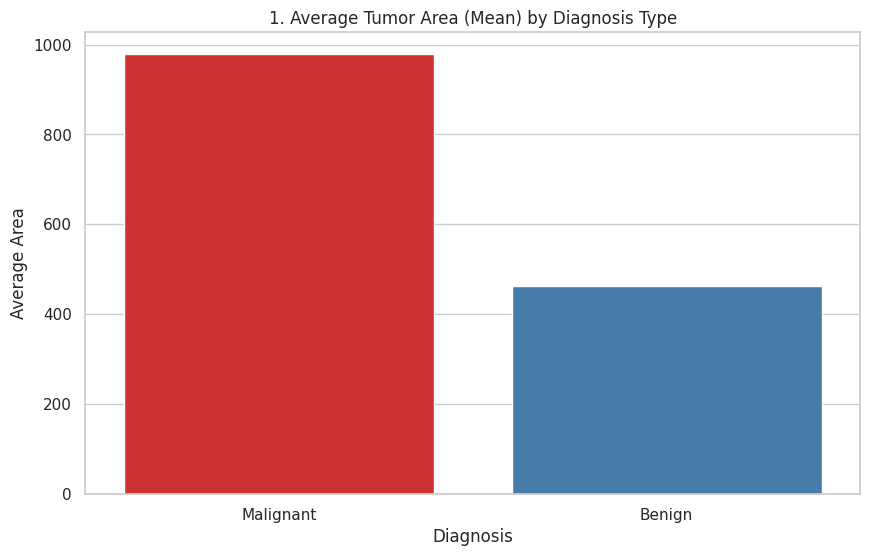

/tmp/ipykernel_2244/1481144500.py:37: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



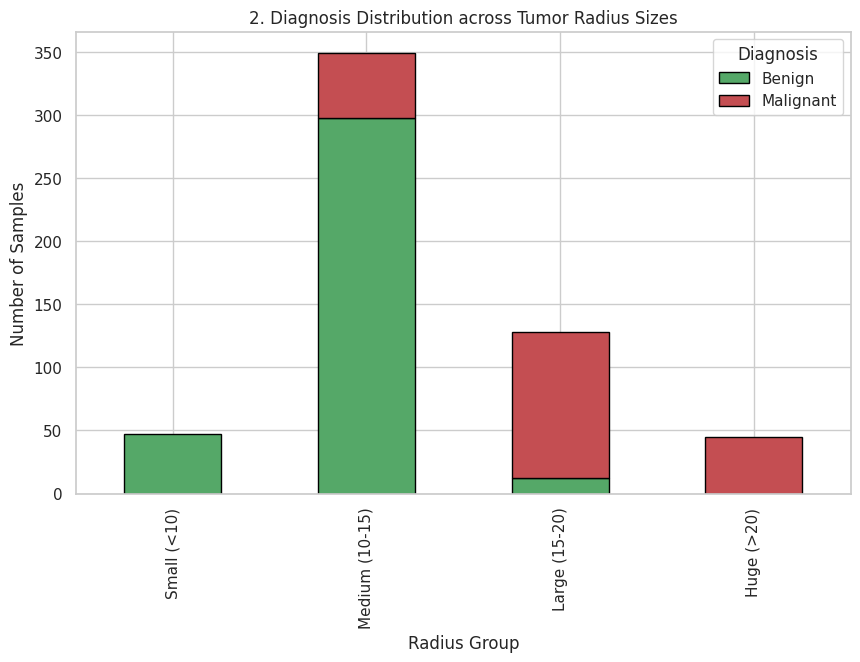

/tmp/ipykernel_2244/1481144500.py:47: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



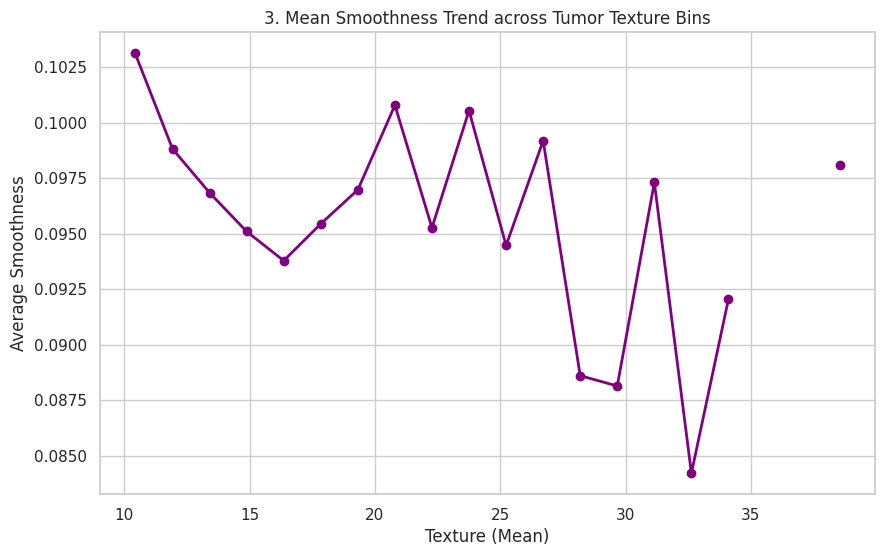

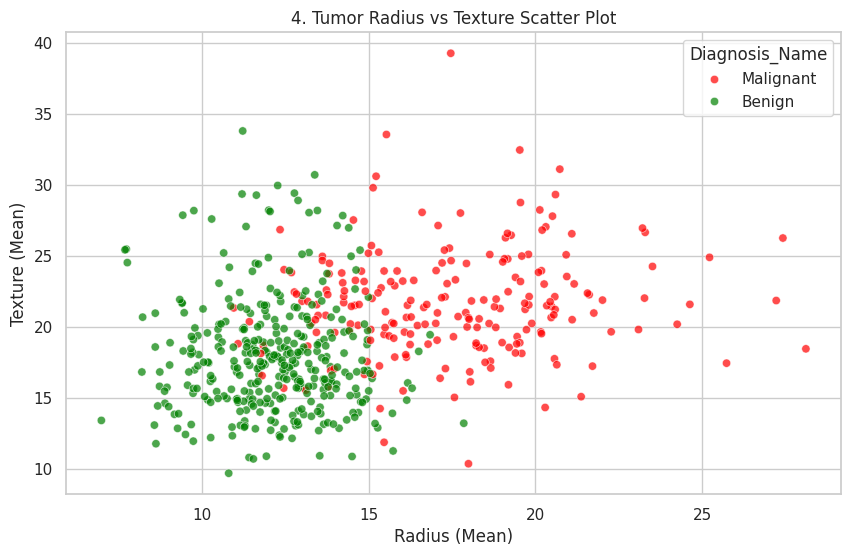

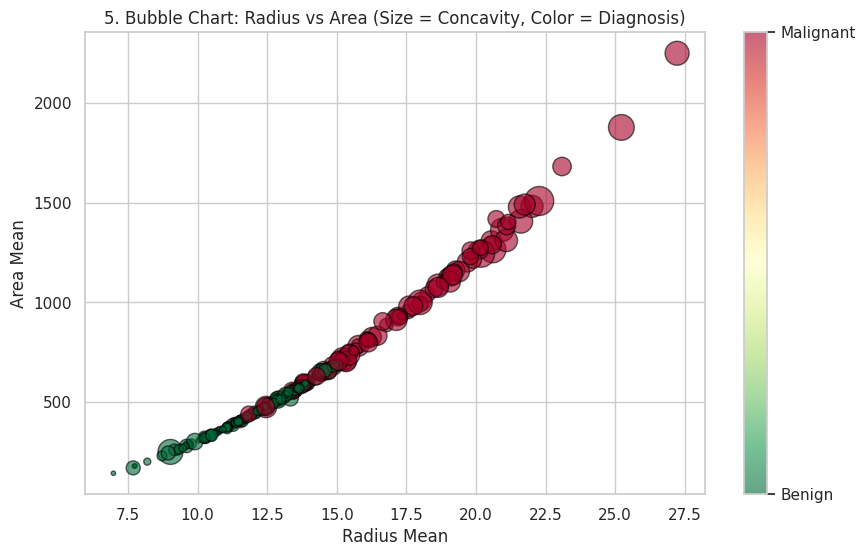

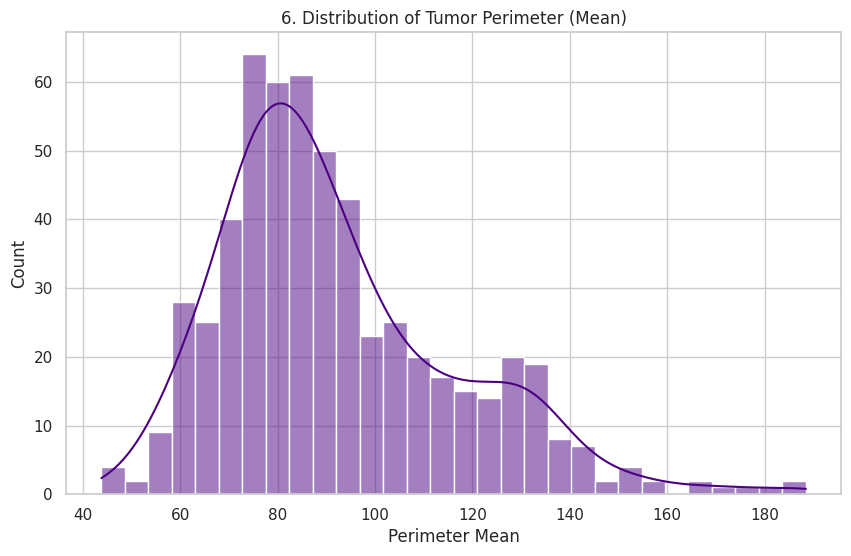

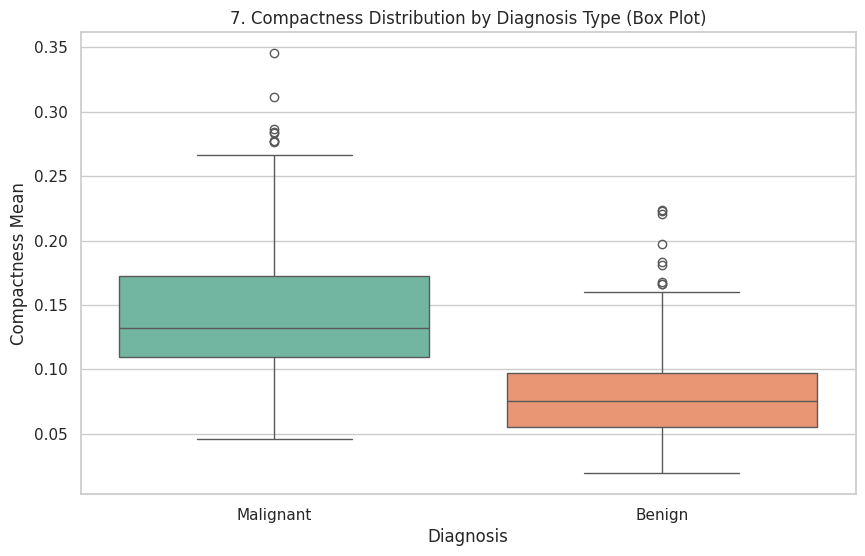

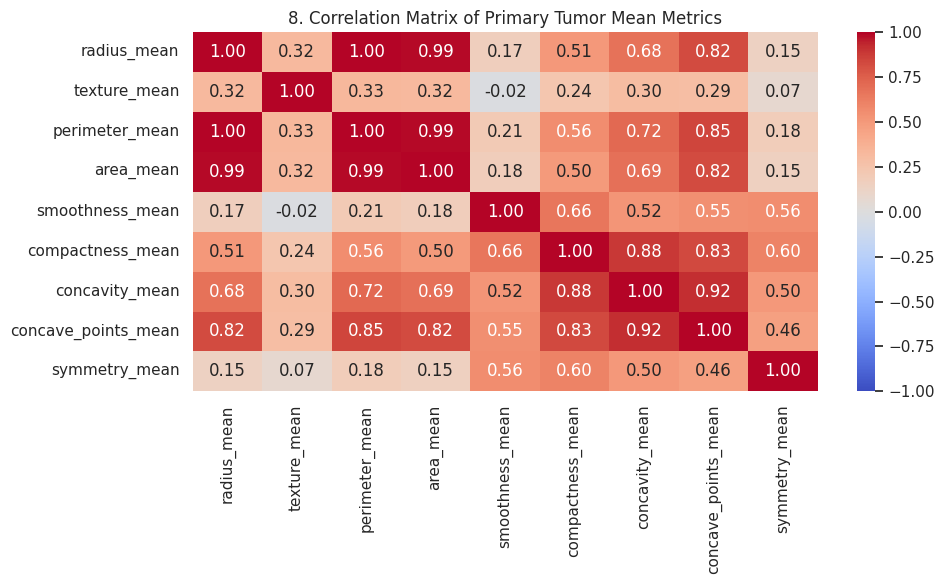

/tmp/ipykernel_2244/1481144500.py:118: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`

/tmp/ipykernel_2244/1481144500.py:123: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



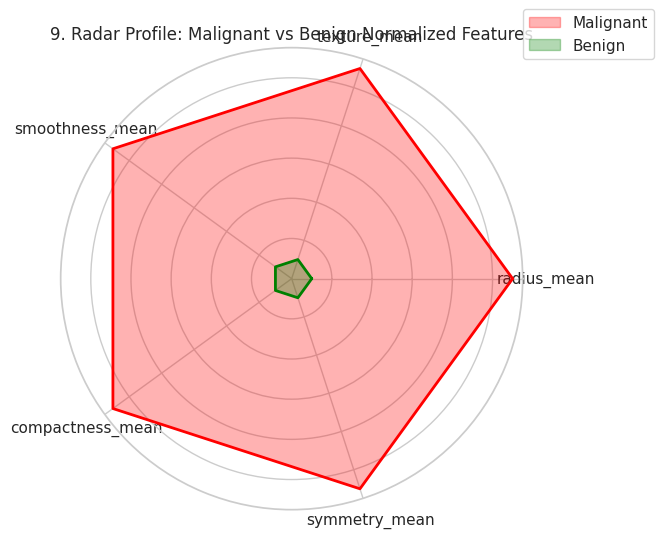

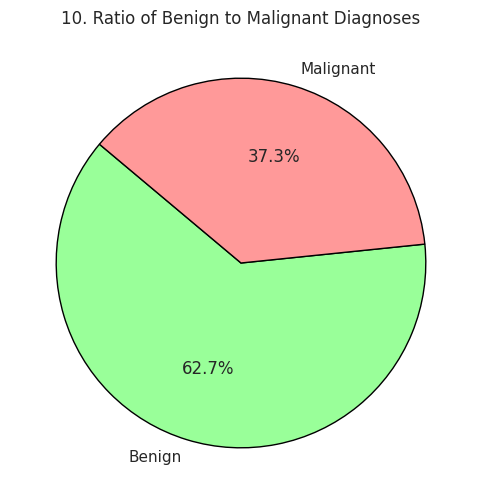

/usr/local/lib/python3.13/dist-packages/plotly/express/_core.py:1727: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



ZeroDivisionError: Weights sum to zero, can't be normalized

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from wordcloud import WordCloud

# 1. Load the WDBC breast cancer dataset
column_names = [
    'ID', 'Diagnosis',
    'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean',
    'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
    'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
    'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se',
    'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst',
    'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst'
]

cancer_df = pd.read_csv('/content/Breast_cancer_dataset/wdbc.data', header=None, names=column_names)
cancer_df['Diagnosis_Name'] = cancer_df['Diagnosis'].map({'M': 'Malignant', 'B': 'Benign'})
print("Dataset shape:", cancer_df.shape)

# Set Seaborn theme
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# --- 1. Bar Chart: Average Mean Area by Diagnosis ---
plt.figure()
sns.barplot(data=cancer_df, x='Diagnosis_Name', y='area_mean', errorbar=None, palette='Set1', hue='Diagnosis_Name', legend=False)
plt.title('1. Average Tumor Area (Mean) by Diagnosis Type')
plt.xlabel('Diagnosis')
plt.ylabel('Average Area')
plt.show()

# --- 2. Stacked Bar Chart: Count of Diagnosis Class by Radius Bins ---
cancer_df['radius_bin'] = pd.cut(cancer_df['radius_mean'], bins=[0, 10, 15, 20, 30], labels=['Small (<10)', 'Medium (10-15)', 'Large (15-20)', 'Huge (>20)'])
pivot_bar = cancer_df.groupby(['radius_bin', 'Diagnosis_Name']).size().unstack(fill_value=0)
pivot_bar.plot(kind='bar', stacked=True, color=['g', 'r'], edgecolor='black')
plt.title('2. Diagnosis Distribution across Tumor Radius Sizes')
plt.xlabel('Radius Group')
plt.ylabel('Number of Samples')
plt.legend(title='Diagnosis')
plt.show()

# --- 3. Line Chart: Trend of Smoothness vs. Texture ---
sorted_df = cancer_df.sort_values(by='texture_mean')
acidity_trend = sorted_df.groupby(pd.cut(sorted_df['texture_mean'], bins=20, duplicates='drop'))['smoothness_mean'].mean().reset_index()
acidity_trend['texture_mid'] = acidity_trend['texture_mean'].apply(lambda x: x.mid if pd.notnull(x) else np.nan)
plt.figure()
plt.plot(acidity_trend['texture_mid'], acidity_trend['smoothness_mean'], marker='o', color='purple', linewidth=2)
plt.title('3. Mean Smoothness Trend across Tumor Texture Bins')
plt.xlabel('Texture (Mean)')
plt.ylabel('Average Smoothness')
plt.show()

# --- 4. Scatter Plot: Radius Mean vs Texture Mean ---
plt.figure()
sns.scatterplot(data=cancer_df, x='radius_mean', y='texture_mean', hue='Diagnosis_Name', palette={'Malignant': 'red', 'Benign': 'green'}, alpha=0.7)
plt.title('4. Tumor Radius vs Texture Scatter Plot')
plt.xlabel('Radius (Mean)')
plt.ylabel('Texture (Mean)')
plt.show()

# --- 5. Bubble Chart: Radius vs Area vs Concavity (Size) and Diagnosis (Color) ---
sample_df = cancer_df.sample(250, random_state=42)
plt.figure()
scatter = plt.scatter(
    x=sample_df['radius_mean'],
    y=sample_df['area_mean'],
    s=sample_df['concavity_mean'] * 1000 + 10,
    c=sample_df['Diagnosis_Name'].map({'Benign': 0, 'Malignant': 1}),
    cmap='RdYlGn_r',
    alpha=0.6,
    edgecolors='black'
)
plt.title('5. Bubble Chart: Radius vs Area (Size = Concavity, Color = Diagnosis)')
plt.xlabel('Radius Mean')
plt.ylabel('Area Mean')
plt.colorbar(scatter, ticks=[0, 1], format=plt.FuncFormatter(lambda val, loc: ['Benign', 'Malignant'][int(val)]))
plt.show()

# --- 6. Histogram: Distribution of Perimeter Mean ---
plt.figure()
sns.histplot(data=cancer_df, x='perimeter_mean', kde=True, color='indigo', bins=30)
plt.title('6. Distribution of Tumor Perimeter (Mean)')
plt.xlabel('Perimeter Mean')
plt.show()

# --- 7. Box Plot: Distribution of Compactness by Diagnosis ---
plt.figure()
sns.boxplot(data=cancer_df, x='Diagnosis_Name', y='compactness_mean', palette='Set2', hue='Diagnosis_Name', legend=False)
plt.title('7. Compactness Distribution by Diagnosis Type (Box Plot)')
plt.xlabel('Diagnosis')
plt.ylabel('Compactness Mean')
plt.show()

# --- 8. Heatmap: Feature Correlation Matrix (Key Mean Metrics) ---
plt.figure()
corr_cols = ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean']
corr_matrix = cancer_df[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('8. Correlation Matrix of Primary Tumor Mean Metrics')
plt.tight_layout()
plt.show()

# --- 9. Radar Chart: Mean Normal Profiles for Malignant vs Benign ---
radar_cols = ['radius_mean', 'texture_mean', 'smoothness_mean', 'compactness_mean', 'symmetry_mean']
group_means = cancer_df.groupby('Diagnosis_Name')[radar_cols].mean()
# Normalize 0.1 to 1.1 for scaling
group_means_norm = (group_means - group_means.min()) / (group_means.max() - group_means.min()) + 0.1

categories_radar = list(group_means_norm.columns)
angles = np.linspace(0, 2*np.pi, len(categories_radar), endpoint=False).tolist() + [0]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))

# Malignant Profile
values_m = group_means_norm.loc['Malignant'].tolist() + [group_means_norm.loc['Malignant'][0]]
ax.fill(angles, values_m, color='red', alpha=0.3, label='Malignant')
ax.plot(angles, values_m, color='red', linewidth=2)

# Benign Profile
values_b = group_means_norm.loc['Benign'].tolist() + [group_means_norm.loc['Benign'][0]]
ax.fill(angles, values_b, color='green', alpha=0.3, label='Benign')
ax.plot(angles, values_b, color='green', linewidth=2)

ax.set_yticklabels([])
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories_radar)
plt.title('9. Radar Profile: Malignant vs Benign Normalized Features')
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()

# --- 10. Pie Chart: Proportional Share of Malignant vs Benign Classes ---
diag_counts = cancer_df['Diagnosis_Name'].value_counts()
plt.figure()
plt.pie(diag_counts, labels=diag_counts.index, autopct='%1.1f%%', startangle=140, colors=['#99ff99','#ff9999'], wedgeprops=dict(edgecolor='black'))
plt.title('10. Ratio of Benign to Malignant Diagnoses')
plt.show()

# --- 11. Tree Map: Hierarchical Category Tree (Diagnosis vs Radius Bins) ---
tree_df = cancer_df.groupby(['Diagnosis_Name', 'radius_bin'], observed=False).size().reset_index(name='count')
fig_tree = px.treemap(
    tree_df,
    path=['Diagnosis_Name', 'radius_bin'],
    values='count',
    color='count',
    color_continuous_scale='RdYlGn_r',
    title='11. Tree Map: Hierarchy of Diagnosis and Radius Bin Sizes'
)
fig_tree.show()

# --- 12. Word Cloud: Text descriptors derived from Diagnosis types ---
descriptors = {
    'Benign': 'regular smooth uniform symmetric light small neat consistent safe tiny gentle flat rounded standard soft clear',
    'Malignant': 'irregular invasive aggressive dense heavy large hard rough asymmetry jagged sharp dark severe complex thick rapid'
}
cancer_df['Descriptors'] = cancer_df['Diagnosis_Name'].map(descriptors)
text_corpus = " ".join(cancer_df['Descriptors'].dropna().tolist())

wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='plasma').generate(text_corpus)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('12. Word Cloud of Tumor Structural Descriptors')
plt.show()

In [ ]:
# Read and display the metadata description from wdbc.names to extract attribute details
with open('/content/Breast_cancer_dataset/wdbc.names', 'r') as f:
    metadata = f.read()

# Print key sections of interest (e.g., Attribute Information, Class distribution)
lines = metadata.split('\n')
printing = False
counter = 0

print("=== Breast Cancer Wisconsin (Diagnostic) Dataset Metadata ===\n")
for line in lines:
    if "Attribute information:" in line or "Attribute Information:" in line or "3. Class distribution" in line or "Number of instances:" in line:
        printing = True
        counter = 0
    if printing:
        print(line)
        counter += 1
        if counter > 35:
            printing = False
            print("... [Truncated for brevity] ...\n")

=== Breast Cancer Wisconsin (Diagnostic) Dataset Metadata ===

5. Number of instances: 569 

6. Number of attributes: 32 (ID, diagnosis, 30 real-valued input features)

7. Attribute information

1) ID number
2) Diagnosis (M = malignant, B = benign)
3-32)

Ten real-valued features are computed for each cell nucleus:

	a) radius (mean of distances from center to points on the perimeter)
	b) texture (standard deviation of gray-scale values)
	c) perimeter
	d) area
	e) smoothness (local variation in radius lengths)
	f) compactness (perimeter^2 / area - 1.0)
	g) concavity (severity of concave portions of the contour)
	h) concave points (number of concave portions of the contour)
	i) symmetry 
	j) fractal dimension ("coastline approximation" - 1)

Several of the papers listed above contain detailed descriptions of
how these features are computed. 

The mean, standard error, and "worst" or largest (mean of the three
largest values) of these features were computed for each image,
resulting in 3

Switzerland Heart Disease Dataset Loaded & Preprocessed.
Dataset Shape: (123, 17)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,Gender,ChestPain,HeartDisease
0,32,1,1,95.0,0,0.0,0.0,127.0,0.0,0.7,1.0,2.0,7.0,1,Male,Typical Angina,Positive
1,34,1,4,115.0,0,0.0,0.0,154.0,0.0,0.2,1.0,2.0,7.0,1,Male,Asymptomatic,Positive
2,35,1,4,125.0,0,0.0,0.0,130.0,1.0,0.3,2.0,2.0,7.0,3,Male,Asymptomatic,Positive
3,36,1,4,110.0,0,0.0,0.0,125.0,1.0,1.0,2.0,2.0,6.0,1,Male,Asymptomatic,Positive
4,38,0,4,105.0,0,0.0,0.0,166.0,0.0,2.8,1.0,2.0,7.0,2,Female,Asymptomatic,Positive


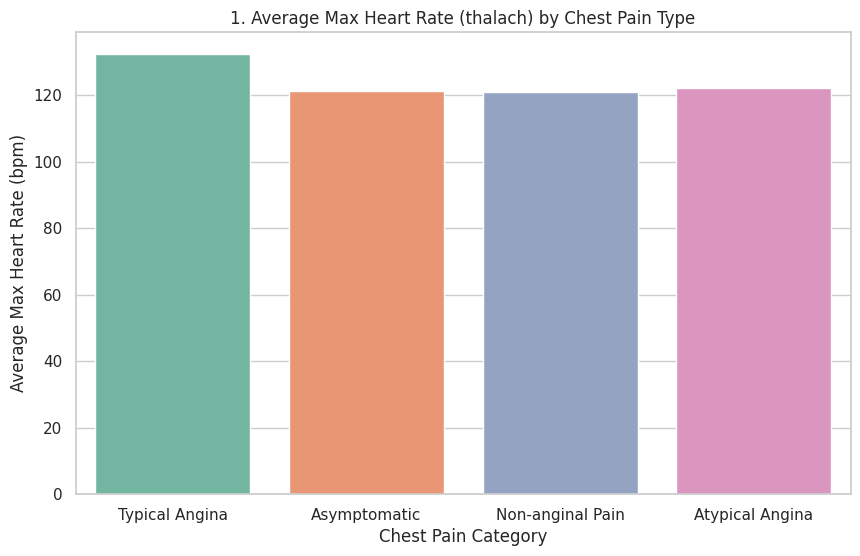

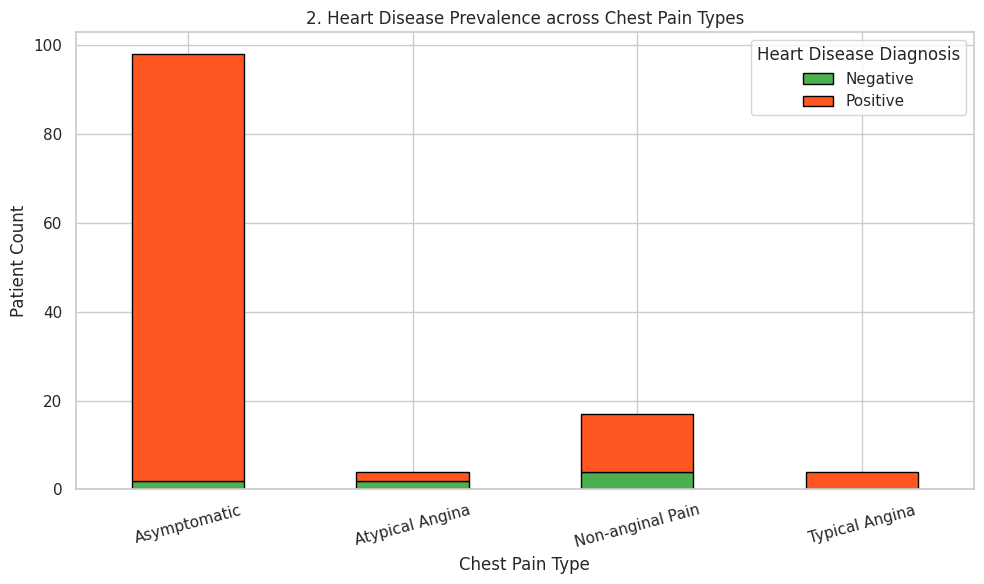

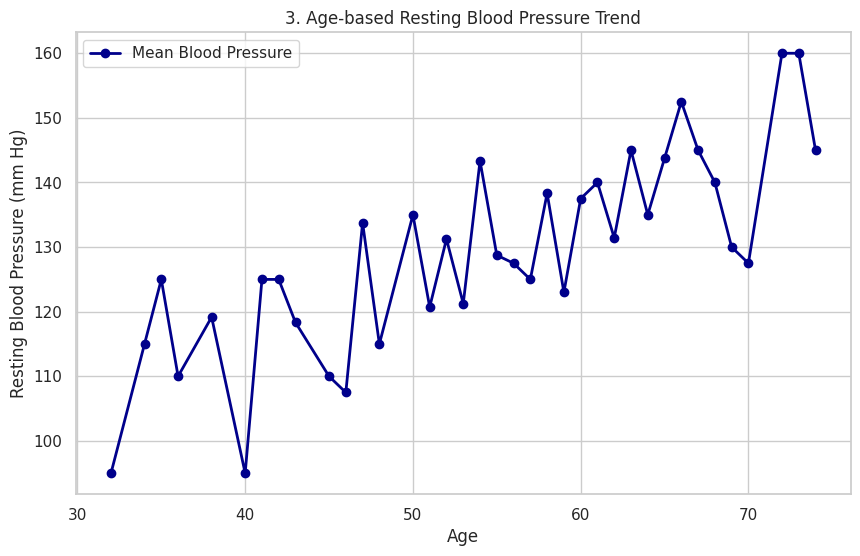

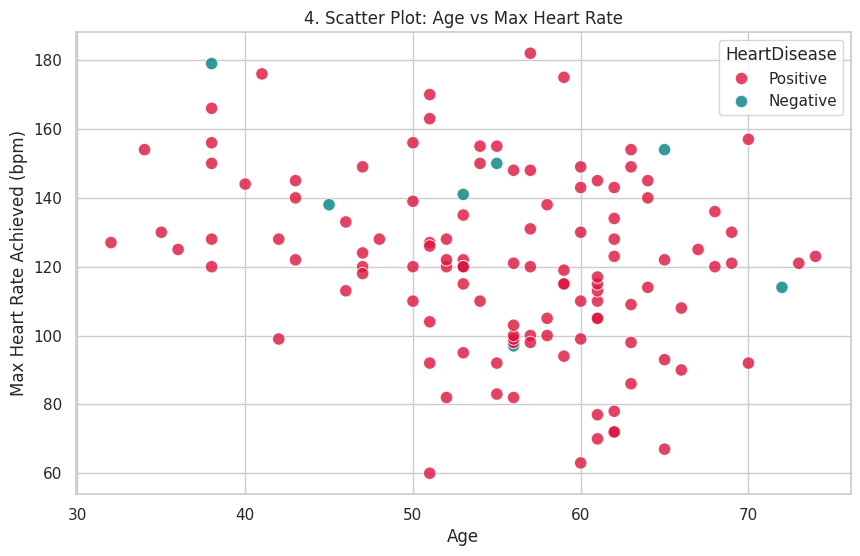

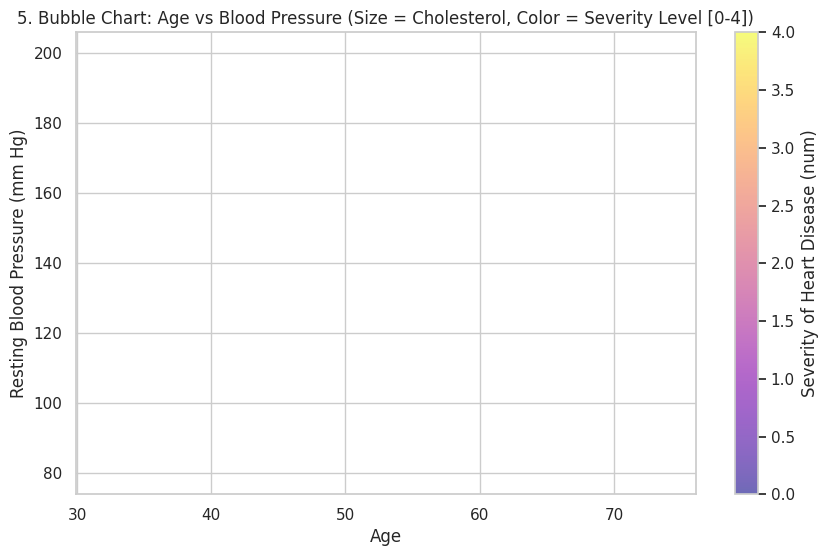

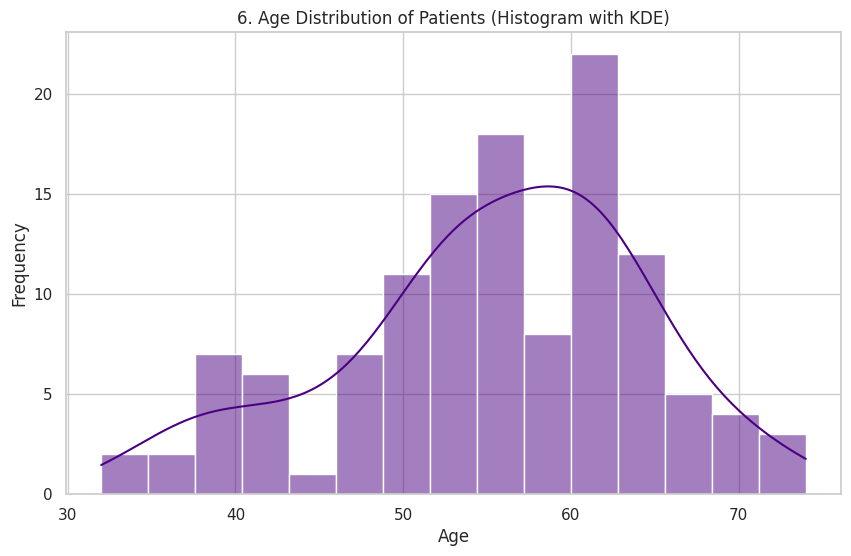

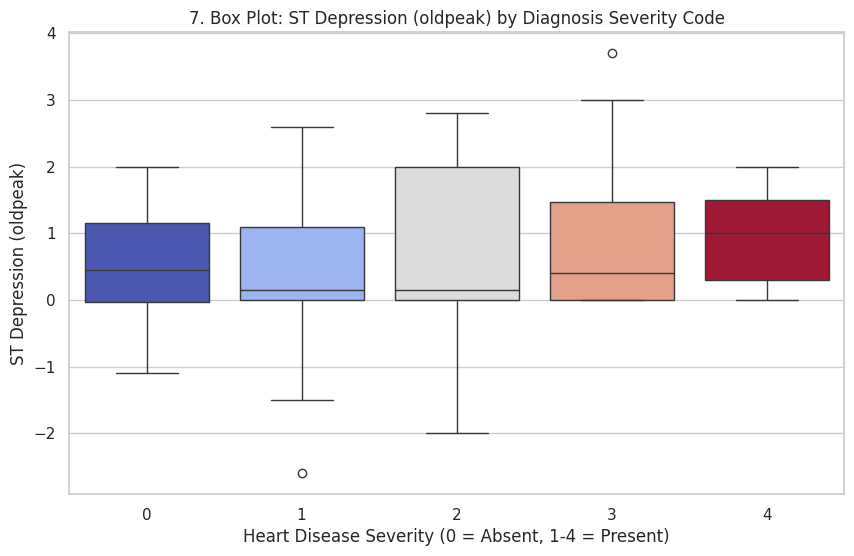

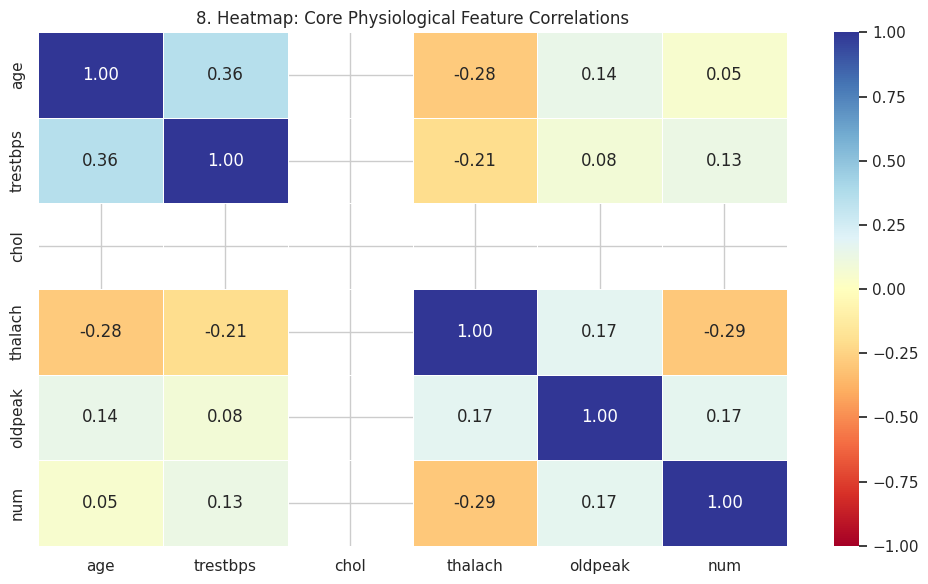

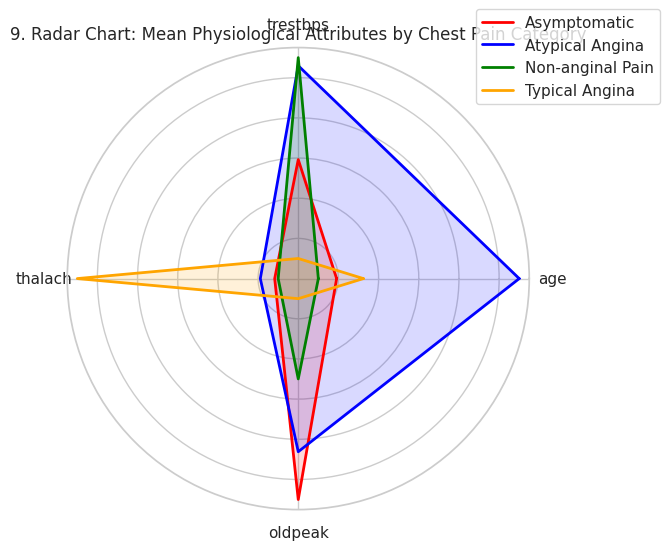

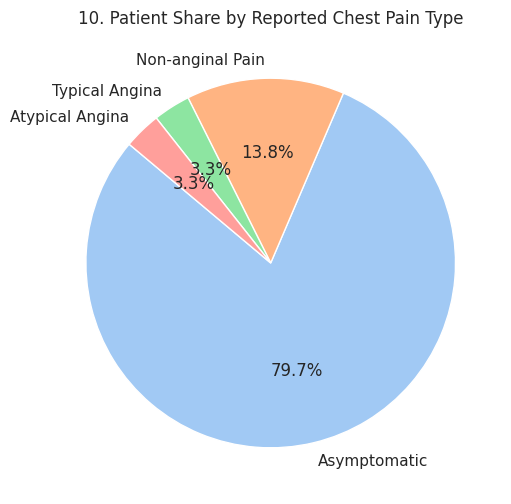

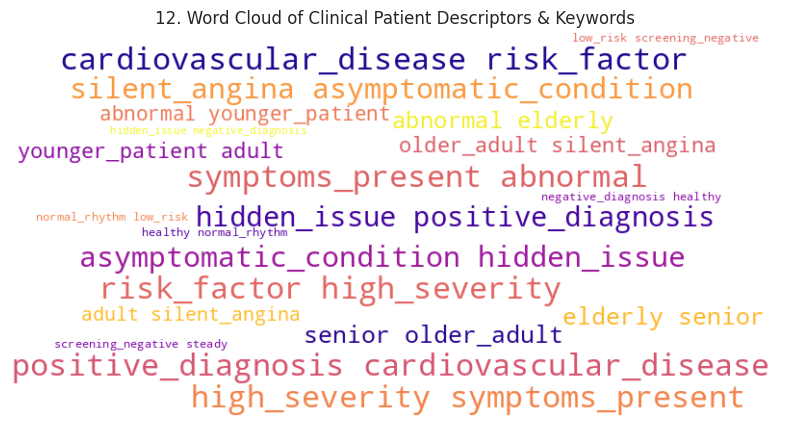

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from wordcloud import WordCloud

# Set plotting styles
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# 1. Load the Switzerland Processed Heart Disease Dataset
# The dataset contains 14 attributes separated by commas
columns = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
    'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'
]

# Reading the data. Missing values are represented as '?' in this dataset
df_heart = pd.read_csv('/content/Heart_disease_dataset/processed.switzerland.data', header=None, names=columns, na_values='?')

# Let's inspect and perform quick cleaning/imputation
# Since some columns have many missing values in the Switzerland subset, we impute them with medians
for col in ['trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']:
    df_heart[col] = df_heart[col].fillna(df_heart[col].median())

# Create categorical maps for plotting labels
df_heart['Gender'] = df_heart['sex'].map({1: 'Male', 0: 'Female'})
df_heart['ChestPain'] = df_heart['cp'].map({1: 'Typical Angina', 2: 'Atypical Angina', 3: 'Non-anginal Pain', 4: 'Asymptomatic'})
df_heart['HeartDisease'] = df_heart['num'].apply(lambda x: 'Positive' if x > 0 else 'Negative')

print("Switzerland Heart Disease Dataset Loaded & Preprocessed.")
print(f"Dataset Shape: {df_heart.shape}")
display(df_heart.head())

# ---------------------------------------------------------------------------
# 1. Bar Chart: Average Maximum Heart Rate (thalach) by Chest Pain Type
# ---------------------------------------------------------------------------
plt.figure()
sns.barplot(data=df_heart, x='ChestPain', y='thalach', estimator=np.mean, errorbar=None, palette='Set2', hue='ChestPain', legend=False)
plt.title('1. Average Max Heart Rate (thalach) by Chest Pain Type')
plt.ylabel('Average Max Heart Rate (bpm)')
plt.xlabel('Chest Pain Category')
plt.show()

# ---------------------------------------------------------------------------
# 2. Stacked Bar Chart: Heart Disease Prevalence across Chest Pain Types
# ---------------------------------------------------------------------------
pivot_df = df_heart.groupby(['ChestPain', 'HeartDisease']).size().unstack(fill_value=0)
pivot_df.plot(kind='bar', stacked=True, color=['#4CAF50', '#FF5722'], edgecolor='black')
plt.title('2. Heart Disease Prevalence across Chest Pain Types')
plt.ylabel('Patient Count')
plt.xlabel('Chest Pain Type')
plt.legend(title='Heart Disease Diagnosis')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------------
# 3. Line Chart: Trend of Blood Pressure (trestbps) across sorted Age groups
# ---------------------------------------------------------------------------
age_trend = df_heart.groupby('age')['trestbps'].mean().reset_index()
plt.figure()
plt.plot(age_trend['age'], age_trend['trestbps'], color='darkblue', marker='o', linewidth=2, label='Mean Blood Pressure')
plt.title('3. Age-based Resting Blood Pressure Trend')
plt.xlabel('Age')
plt.ylabel('Resting Blood Pressure (mm Hg)')
plt.legend()
plt.show()

# ---------------------------------------------------------------------------
# 4. Scatter Plot: Age vs Maximum Heart Rate (thalach) colored by Diagnosis
# ---------------------------------------------------------------------------
plt.figure()
sns.scatterplot(data=df_heart, x='age', y='thalach', hue='HeartDisease', palette={'Positive': 'crimson', 'Negative': 'teal'}, alpha=0.8, s=80)
plt.title('4. Scatter Plot: Age vs Max Heart Rate')
plt.xlabel('Age')
plt.ylabel('Max Heart Rate Achieved (bpm)')
plt.show()

# ---------------------------------------------------------------------------
# 5. Bubble Chart: Age vs Blood Pressure (Size = Cholesterol, Color = Heart Disease Status)
# ---------------------------------------------------------------------------
plt.figure()
# Since cholesterol contains many imputed/constant or high values, we scale it for visual representation
scatter = plt.scatter(
    x=df_heart['age'],
    y=df_heart['trestbps'],
    s=df_heart['chol'] * 0.8,
    c=df_heart['num'],
    cmap='plasma',
    alpha=0.6,
    edgecolors='black'
)
plt.title('5. Bubble Chart: Age vs Blood Pressure (Size = Cholesterol, Color = Severity Level [0-4])')
plt.xlabel('Age')
plt.ylabel('Resting Blood Pressure (mm Hg)')
plt.colorbar(scatter, label='Severity of Heart Disease (num)')
plt.show()

# ---------------------------------------------------------------------------
# 6. Histogram: Age distribution of Patients
# ---------------------------------------------------------------------------
plt.figure()
sns.histplot(df_heart['age'], bins=15, kde=True, color='indigo')
plt.title('6. Age Distribution of Patients (Histogram with KDE)')

plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

# ---------------------------------------------------------------------------
# 7. Box Plot: Distribution of ST Depression (oldpeak) by Severity Level
# ---------------------------------------------------------------------------
plt.figure()
sns.boxplot(data=df_heart, x='num', y='oldpeak', palette='coolwarm', hue='num', legend=False)
plt.title('7. Box Plot: ST Depression (oldpeak) by Diagnosis Severity Code')
plt.xlabel('Heart Disease Severity (0 = Absent, 1-4 = Present)')
plt.ylabel('ST Depression (oldpeak)')
plt.show()

# ---------------------------------------------------------------------------
# 8. Heatmap: Correlation of Numerical Variables
# ---------------------------------------------------------------------------
plt.figure()
corr = df_heart[['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'num']].corr()
sns.heatmap(corr, annot=True, cmap='RdYlBu', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5)
plt.title('8. Heatmap: Core Physiological Feature Correlations')
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------------
# 9. Radar Chart: Mean Physiological Metrics across Chest Pain Types
# ---------------------------------------------------------------------------
# Aggregate numerical metrics and normalize them
metrics = ['age', 'trestbps', 'thalach', 'oldpeak']
cp_means = df_heart.groupby('ChestPain')[metrics].mean()
cp_means_norm = (cp_means - cp_means.min()) / (cp_means.max() - cp_means.min()) + 0.1

categories_list = list(cp_means_norm.columns)
angles = np.linspace(0, 2*np.pi, len(categories_list), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
colors = ['red', 'blue', 'green', 'orange']

for i, chest_pain_type in enumerate(cp_means_norm.index):
    values = cp_means_norm.loc[chest_pain_type].tolist()
    values += values[:1]
    ax.fill(angles, values, color=colors[i], alpha=0.15)
    ax.plot(angles, values, color=colors[i], linewidth=2, label=chest_pain_type)

ax.set_yticklabels([])
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories_list)
plt.title('9. Radar Chart: Mean Physiological Attributes by Chest Pain Category')
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()

# ---------------------------------------------------------------------------
# 10. Pie Chart: Proportional Share of Patients by Chest Pain Type
# ---------------------------------------------------------------------------
cp_counts = df_heart['ChestPain'].value_counts()
plt.figure()
plt.pie(cp_counts, labels=cp_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('10. Patient Share by Reported Chest Pain Type')
plt.show()

# ---------------------------------------------------------------------------
# 11. Tree Map: Proportions of Diagnosis Severity nested under Chest Pain Types
# ---------------------------------------------------------------------------
tree_df = df_heart.groupby(['ChestPain', 'HeartDisease']).size().reset_index(name='count')
fig_tree = px.treemap(
    tree_df,
    path=['ChestPain', 'HeartDisease'],
    values='count',
    title='11. Tree Map: Patient Hierarchy of Chest Pain Categories and Heart Disease Status',
    color='count',
    color_continuous_scale='Blues'
)
fig_tree.show()

# ---------------------------------------------------------------------------
# 12. Word Cloud: Symptoms and Medical Indicators
# ---------------------------------------------------------------------------
# Map patient records to descriptive keyword strings based on age group and diagnosis status
def map_descriptors(row):
    desc = []
    if row['HeartDisease'] == 'Positive':
        desc.append("positive_diagnosis cardiovascular_disease risk_factor high_severity symptoms_present abnormal")
    else:
        desc.append("negative_diagnosis healthy normal_rhythm low_risk screening_negative steady")
    if row['age'] > 55:
        desc.append("elderly senior older_adult")
    else:
        desc.append("younger_patient adult")
    if row['ChestPain'] == 'Asymptomatic':
        desc.append("silent_angina asymptomatic_condition hidden_issue")
    return " ".join(desc)

df_heart['Medical_Keywords'] = df_heart.apply(map_descriptors, axis=1)
text_corpus = " ".join(df_heart['Medical_Keywords'].dropna().tolist())

wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='plasma', random_state=42).generate(text_corpus)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('12. Word Cloud of Clinical Patient Descriptors & Keywords')
plt.show()
